<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [hopforge](https://github.com/Gokaran-Shukla/hopforge) · MIT License — any reuse must keep this copyright notice and credit the author.

# 17 · Step by step: build a new Hamiltonian from a paper and simulate it

We rebuild, from scratch, the **Lieb-lattice topological insulator of Weeks & Franz**
(PRB 82, 085310 (2010)) and take it through every stage of a real study:

1. Write down the Hamiltonian.
2. Define the lattice and orbitals.
3. Check the geometry (neighbour shells).
4. Add hoppings, including complex spin-orbit phases.
5. Check Hermiticity and symmetries.
6. Bands and DOS.
7. Topology (Z2), compared with the paper.
8. Edge states (bulk-boundary correspondence).
9. Quantum transport through a device with disorder.
10. Parameter scans and a phase diagram (in parallel).
11. Package it: register the model and write a test.

$$H=-t\sum_{\langle ij\rangle\sigma}c^\dagger_{i\sigma}c_{j\sigma}
+i\lambda\sum_{\langle\langle ij\rangle\rangle}\nu_{ij}\,c^\dagger_i\sigma_z c_j,
\qquad \nu_{ij}=\pm1 \text{ (hopping turns left/right through the corner site)}$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline
from hopforge import transport as tr
from hopforge.models._util import chirality

## Step 1-2: lattice and orbitals
The Lieb lattice has three sites per square cell: a corner (Cu) and two edge centres (Ox, Oy). Positions are fractional.

In [2]:
lat = hf.Lattice([[1, 0], [0, 1]],
                 [("Cu", [0.0, 0.0]), ("Ox", [0.5, 0.0]), ("Oy", [0.0, 0.5])])
model = hf.Model(lat, spinful=True, name="Weeks-Franz Lieb TI")
print(model)

<Model 'Weeks-Franz Lieb TI': dim=2, orbitals=3, spinful=True, bands=6>


## Step 3: inspect the geometry before adding anything
Which bonds are 1st, 2nd and 3rd neighbours? The SOC term lives on the 2nd-neighbour Ox–Oy bonds.

shell 1: d = 0.500  pairs = [('Cu', 'Ox'), ('Cu', 'Oy')]
shell 2: d = 0.707  pairs = [('Ox', 'Oy')]
shell 3: d = 1.000  pairs = [('Cu', 'Cu'), ('Ox', 'Ox'), ('Oy', 'Oy')]


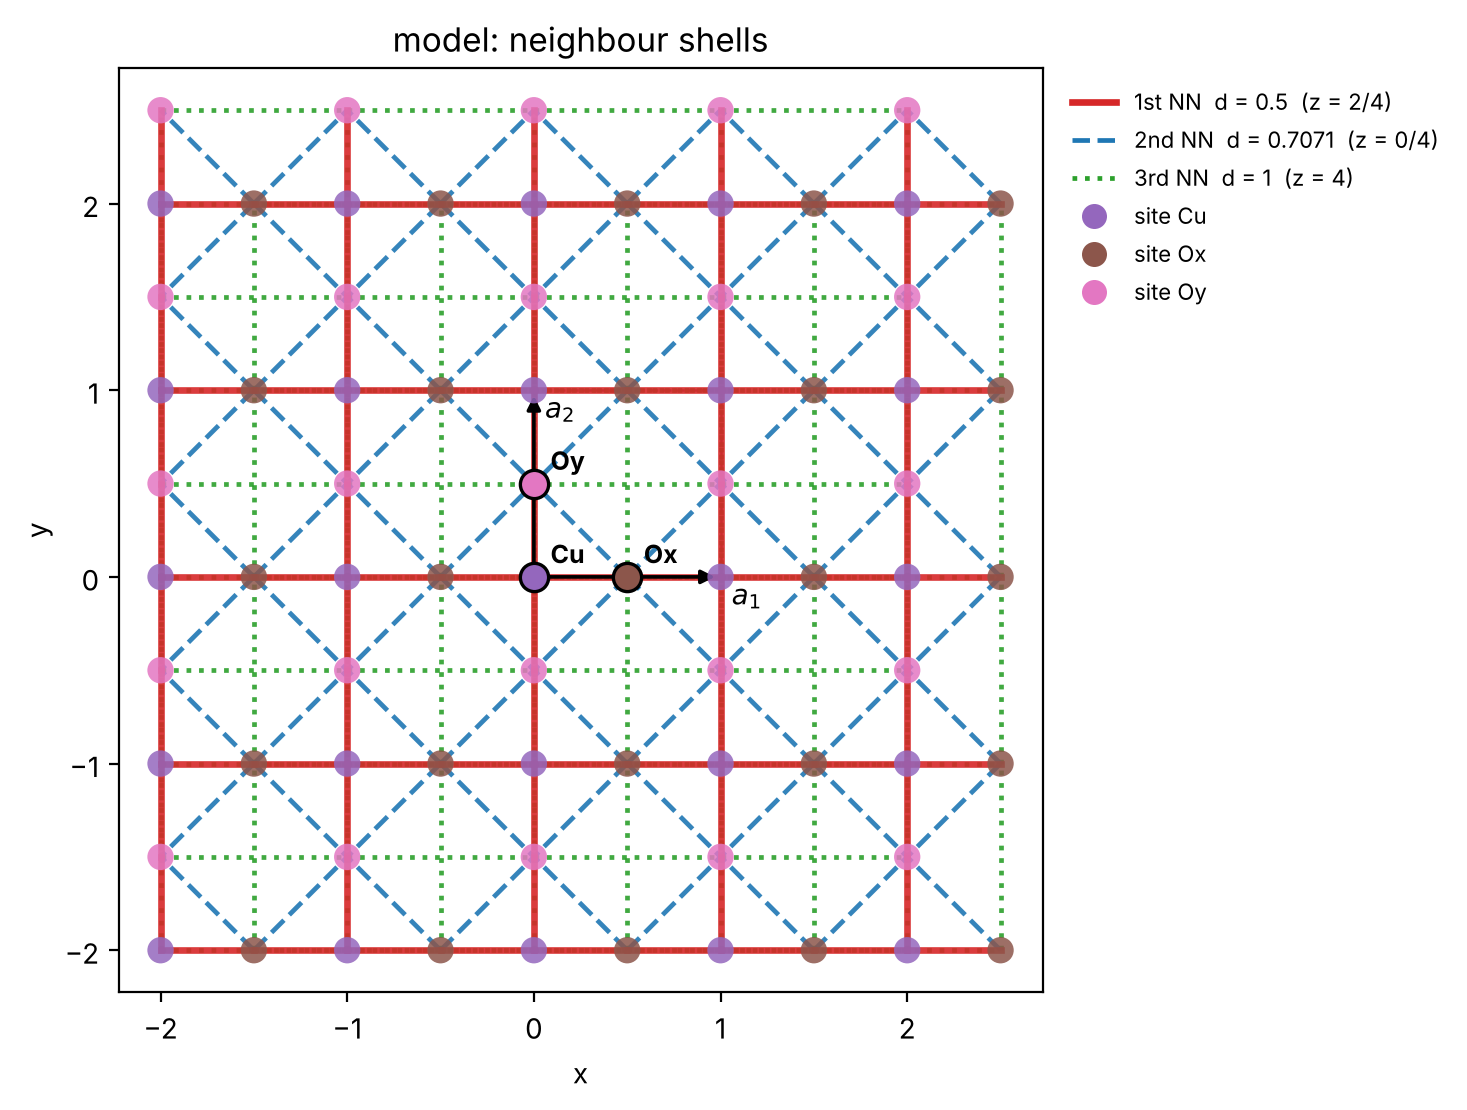

In [3]:
bare = hf.Model(lat)            # spinless copy for drawing
hf.plot_lattice(bare, shells=3);
for n, sh in enumerate(hf.plotting.neighbor_shells(bare, 3), 1):
    pairs = {(bare.lat.names[i], bare.lat.names[j]) for i, j, R, d in sh["bonds"]}
    print(f"shell {n}: d = {sh['distance']:.3f}  pairs = {sorted(pairs)}")

## Step 4: hoppings
NN hopping on shell 1. For the SOC we loop over the 2nd-shell Ox–Oy bonds and compute the chirality ν from the path through the shared Cu neighbour. The Hermitian conjugate is added automatically.

In [4]:
t, lam = 1.0, 0.2
model.add_neighbors(-t, shell=1)
nso = 0
for i, j, R, d in model.neighbors(2):
    if {model.lat.names[i], model.lat.names[j]} == {"Ox", "Oy"}:
        nu = chirality(model, i, j, R, nn_dist=0.5)
        model.add_hopping(1j * lam * nu * hf.pauli("z"), i, j, R)
        nso += 1
print("SOC bonds per cell:", nso)
model.special_points = {"G": np.zeros(2), "X": np.array([0.5, 0]), "M": np.array([0.5, 0.5])}
print(model.summary())

SOC bonds per cell: 4
hopforge Model 'Weeks-Franz Lieb TI'
  periodic dims : 2   (space dim 2)
  orbitals      : 3  ['Cu', 'Ox', 'Oy']
  spinful       : True  -> 6 bands
  hopping terms : 8 (+ h.c.)
  special points: ['G', 'X', 'M']


## Step 5: sanity checks: Hermiticity, time reversal, S_z conservation

In [5]:
k = np.random.rand(5, 2)
H = model.hamiltonian(k)
print("Hermitian:", np.allclose(H, H.conj().transpose(0, 2, 1)))
# time reversal: Theta = i s_y K  ->  H(-k) = T H(k)* T^-1
T = np.kron(np.eye(3), 1j * hf.pauli('y'))
print("TRS:", np.allclose(model.hamiltonian(-k), T @ H.conj() @ T.conj().T))
Sz = model.spin_operator('z')
print("[H, S_z] = 0:", np.allclose(H @ Sz - Sz @ H, 0))

Hermitian: True
TRS: True
[H, S_z] = 0: True


## Step 6: bands and DOS
Without SOC there is a flat band touching a Dirac cone at M. The SOC gaps it out.

gaps: 0.7999999999999973 0.7999999999999974


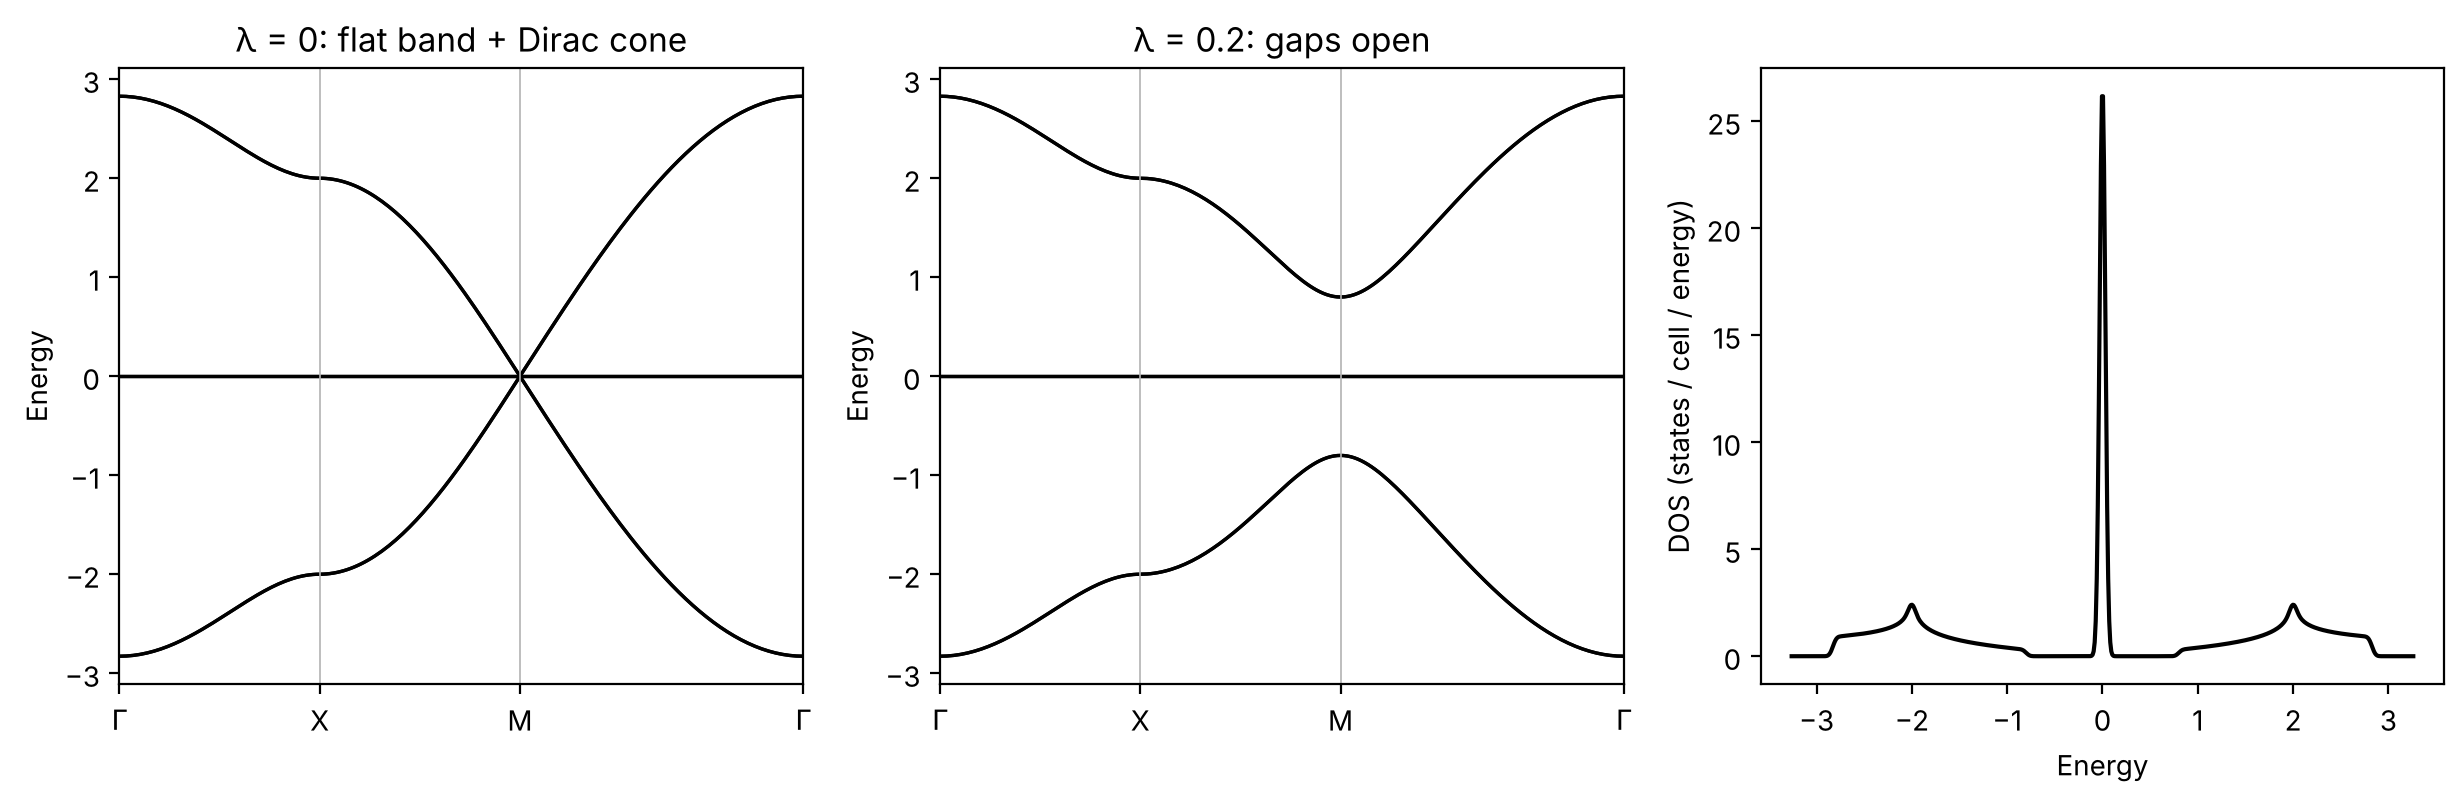

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
m0 = hf.models.lieb().make_spinful(); m0.special_points = model.special_points
m0.plot_bands(["G", "X", "M", "G"], ax=ax[0], title="λ = 0: flat band + Dirac cone")
model.plot_bands(["G", "X", "M", "G"], ax=ax[1], title=f"λ = {lam}: gaps open")
hf.plot_dos(hf.dos(model, nk=150, sigma=0.03), ax=ax[2])
print("gaps:", hf.band_gap(model, 2, 60), hf.band_gap(model, 4, 60))

## Step 7: topology, compared with the paper
Weeks & Franz find a Z2 topological insulator at 1/3 and 2/3 filling.

Z2 (1/3 filling) = 1   Z2 (2/3 filling) = 1


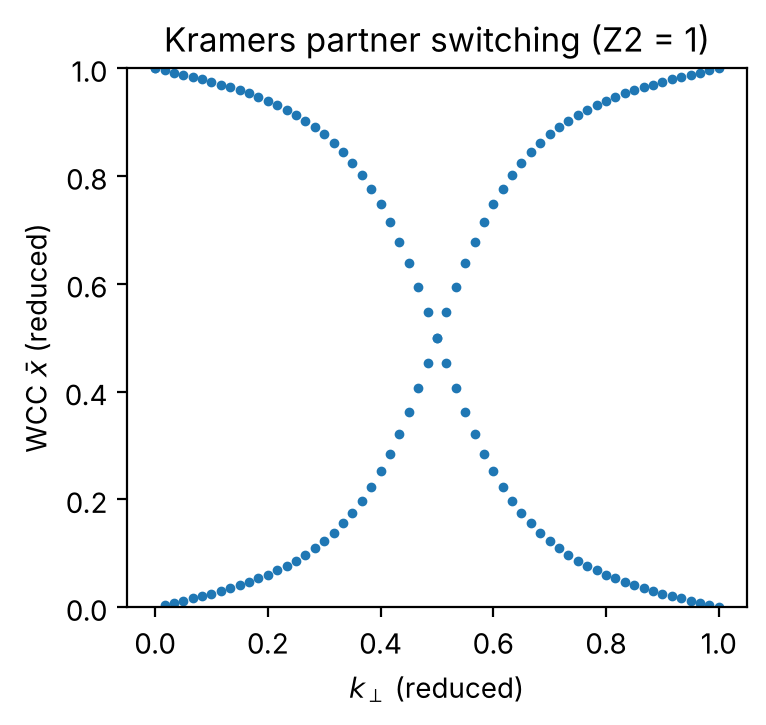

In [7]:
print("Z2 (1/3 filling) =", hf.z2_invariant(model, 2), "  Z2 (2/3 filling) =", hf.z2_invariant(model, 4))
ks, wcc = hf.wilson_loop(model, 2, nscan=61)
hf.plot_wcc(wcc, kperp=ks, title="Kramers partner switching (Z2 = 1)");

## Step 8: edge states (bulk-boundary correspondence)

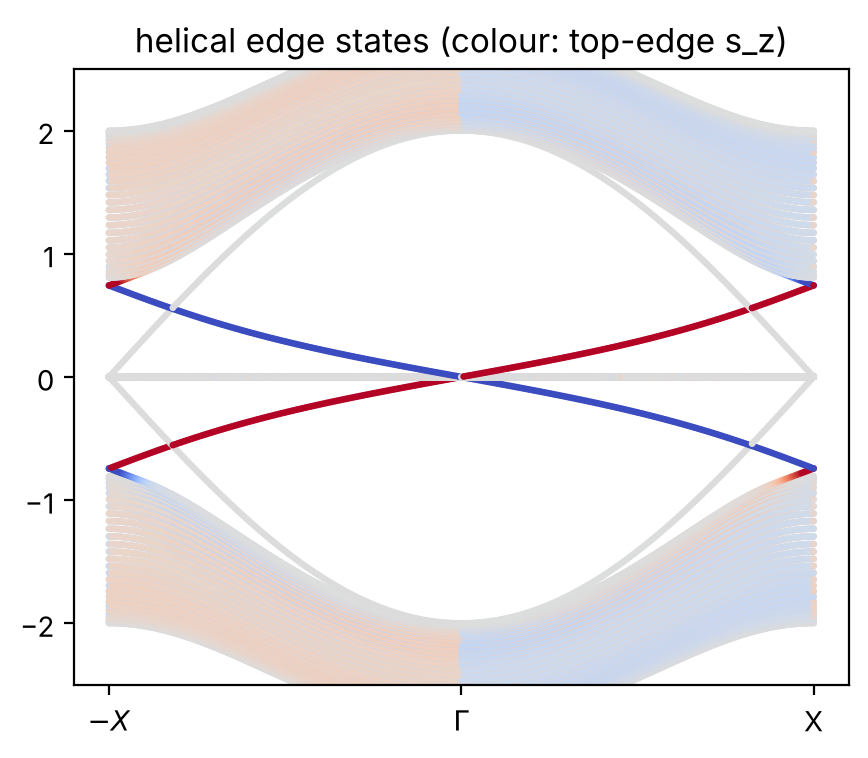

In [8]:
rib = model.ribbon(1, 30)
b = hf.bands(rib, ["-X", "G", "X"], n=300, vectors=True)
w = b.weights(rib.spin_operator('z') @ rib.projector(list(range(rib.norb - 6, rib.norb))))
fig, ax = plt.subplots(figsize=(5, 4))
for n in range(rib.nbands):
    ax.scatter(b.x, b.energies[:, n], c=w[:, n], s=2, cmap="coolwarm", vmin=-0.3, vmax=0.3)
ax.set_ylim(-2.5, 2.5); ax.set_xticks(b.path.ticks); ax.set_xticklabels(b.path.labels)
ax.set_title("helical edge states (colour: top-edge s_z)");

## Step 9: quantum transport through a disordered device
Inside the gap the helical edges carry exactly 2e²/h and are immune to non-magnetic disorder.

In [9]:
Ek = model.energies(hf.kmesh(model, 60))
E_in_gap = 0.5 * (Ek[:, 1].max() + Ek[:, 2].min())     # middle of the gap at 1/3 filling
print("probing at E =", round(E_in_gap, 3), " (gap edges", round(Ek[:, 1].max(), 3), round(Ek[:, 2].min(), 3), ")")
for W in (0.0, 1.0):
    dev = tr.System(model, lambda r: 0 <= r[0] < 20 and 0 <= r[1] < 15, onsite=tr.anderson(W, seed=2) if W else None)
    dev.attach_lead((-1, 0)); dev.attach_lead((1, 0))
    print(f"disorder W = {W}: T = {dev.transmission(1, 0, E_in_gap):.4f} (e²/h)")

probing at E = -0.4  (gap edges -0.8 -0.0 )


disorder W = 0.0: T = 2.0000 (e²/h)


disorder W = 1.0: T = 2.0000 (e²/h)


## Step 10: parameter scan and phase diagram
Add a potential ±Δ on Ox/Oy (it breaks C4, like uniaxial strain) that competes with λ, then map Z2 in parallel. (A Cu/O offset is *not* enough: it never closes the gap at 1/3 filling. Try it.)

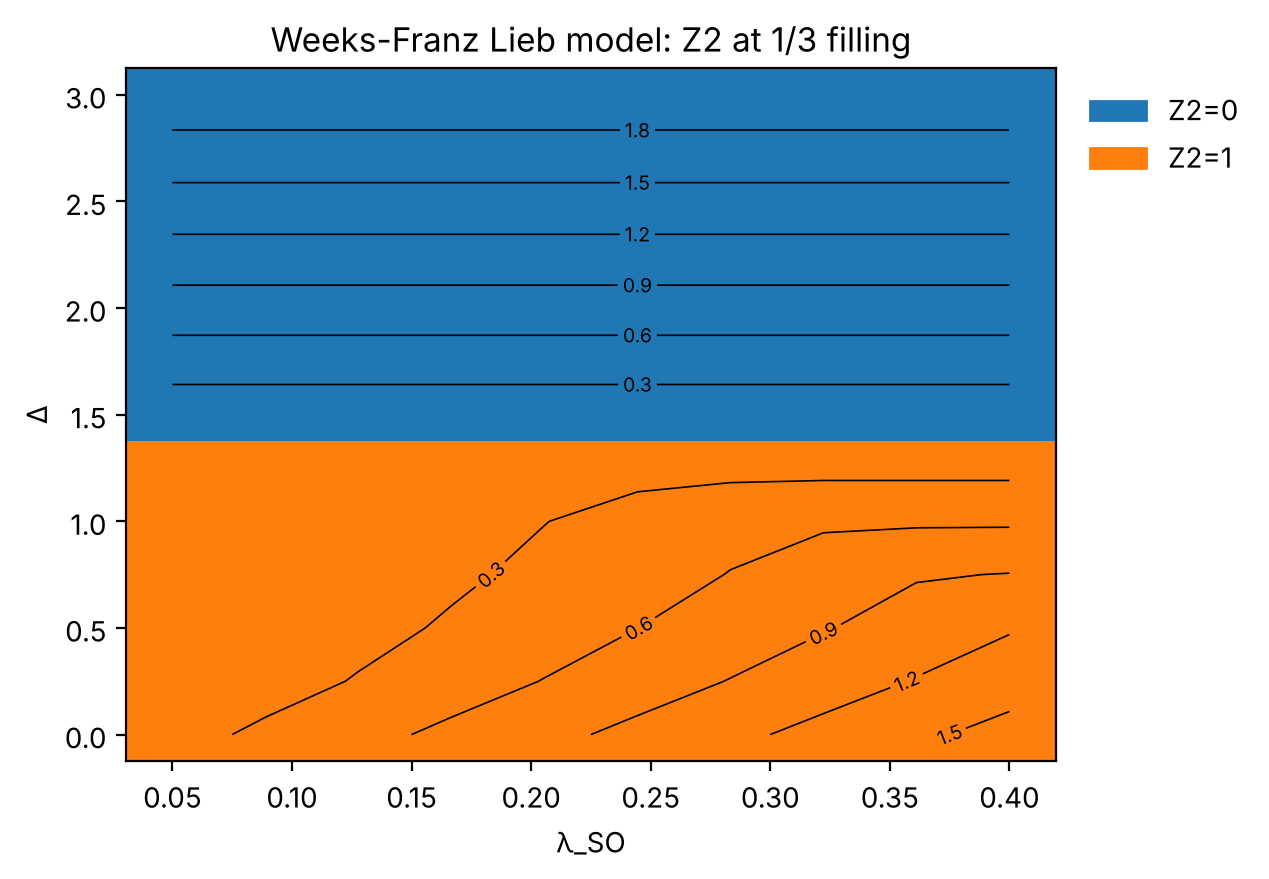

In [10]:
def build(lam, delta):
    m = hf.Model(lat, spinful=True)
    m.add_neighbors(-1.0, 1)
    for i, j, R, d in m.neighbors(2):
        if {m.lat.names[i], m.lat.names[j]} == {"Ox", "Oy"}:
            m.add_hopping(1j * lam * chirality(m, i, j, R, 0.5) * hf.pauli("z"), i, j, R)
    m.add_onsite(delta, "Ox"); m.add_onsite(-delta, "Oy")
    return m
pd = hf.phases.topological_phase_diagram(build, "λ_SO", np.linspace(0.05, 0.4, 10), "Δ", np.linspace(0, 3.0, 13),
                                          occ=2, invariant="z2", nk=30, n_jobs=-1)
hf.phases.plot_phase_diagram(pd, contour="gap", title="Weeks-Franz Lieb model: Z2 at 1/3 filling");

## Step 11: package your model for the community
```python
@hf.models.register_model("weeks_franz_lieb", 2, "Lieb-lattice Z2 TI, Weeks & Franz PRB 82, 085310 (2010)")
def weeks_franz_lieb(t=1.0, lam=0.2, delta=0.0):
    ...                       # the code of Steps 2-4
    return m

# tests/test_my_model.py
def test_weeks_franz_z2():
    assert hf.z2_invariant(hf.models.get("weeks_franz_lieb"), 2) == 1
```
Then open a pull request (see CONTRIBUTING.md). Every model enters the library with a test against a published result.

---
## Quiz 17: Building a Hamiltonian step by step

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [11]:
quiz = hf.Quiz(17)
quiz.interactive()

In [12]:
quiz.show()

=== Quiz 17: Building a new Hamiltonian step by step ===

Q1. The first thing to do when implementing a model from a paper is
   (a) write down H and its conventions (signs, units, lattice, orbital positions)
   (b) add disorder
   (c) plot DOS
   (d) compute transport

Q2. Before adding hoppings it is useful to
   (a) run ED
   (b) compute the Chern number
   (c) plot the lattice and list the neighbour shells
   (d) set the Fermi level

Q3. In the Weeks-Franz Lieb model, intrinsic SOC acts on
   (a) third neighbours only
   (b) first-neighbour Cu-O bonds
   (c) Cu on-site
   (d) second-neighbour Ox-Oy bonds

Q4. The chirality nu_ij of a Kane-Mele-type term is
   (a) the bond length
   (b) the sign of (d1 x d2)_z along the two-step path i -> k -> j
   (c) random
   (d) always +1

Q5. A quick numerical test of time-reversal symmetry for spin-1/2 is
   (a) H(k) = H(-k)
   (b) H = H^T
   (c) Tr H = 0
   (d) H(-k) = T H(k)* T^-1 with T = i s_y (x) 1

Q6. If [H, S_z] = 0, the Z2 invariant e

In [13]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0